# US Consumer Trends — Selected Charts
Ten figures matching the selected charts, in the same order. Run all cells from top to bottom.
Dependencies: `pip install pandas numpy requests matplotlib openpyxl ipykernel`

Keep `ce_mean.xlsx` and `ce_shares.xlsx` in the working folder beside this notebook.
BLS expenditure data come from those files; all other data are downloaded fresh on each run.
No API keys or data caches are needed. The cutoff is today; figures are saved to `outputs/simple`.

In [1]:
from pathlib import Path
from io import BytesIO
import re
import zipfile
import numpy as np
import pandas as pd
import requests
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Image

AS_OF = pd.Timestamp.today().normalize()
INCOME_CHART_START = '2025'  # Set to '2010' to display the longer income history.
OUT = Path('outputs/simple')
OUT.mkdir(parents=True, exist_ok=True)
Q = ['0–20%', '20–40%', '40–60%', '60–80%', '80–100%']
COLORS = ['#0c5369', '#238b8e', '#86b9ad', '#ce9e4c', '#924659']
plt.rcParams.update({'figure.figsize': (12, 4.8), 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.alpha': .2, 'axes.axisbelow': True,
    'axes.prop_cycle': plt.cycler(color=COLORS)})

### Load the data
Three public FRED CSV downloads supply BEA income/spending, Fed debt-service ratios and BLS CPI.
FRED limits each download to 12 series. Monthly and quarterly series are requested separately.
Public downloads supply distributions, wages, wealth and debt; BLS expenditure workbooks are local.
Downloads are read directly from memory, with no local fallback.

In [2]:
def download(url):
    response = requests.get(url, timeout=45)
    response.raise_for_status()
    return BytesIO(response.content)

SERIES = {'dpi':'DSPI', 'rdpi':'DSPIC96', 'pce':'PCE', 'rpce':'PCEC96',
    'pcepi':'PCEPI', 'energy':'DNRGRC1M027SBEA', 'compensation':'W209RC1',
    'proprietors':'A041RC1', 'rent':'A048RC1', 'interest':'PII', 'dividends':'PDI',
    'transfers':'PCTR', 'social_insurance':'A061RC1', 'taxes':'W055RC1',
    'cpi':'CPIAUCNS', 'cpi_ex_energy':'CPILEGNS',
    'Total':'TDSP', 'Mortgage':'MDSP', 'Consumer':'CDSP'}

def fred(ids):
    return pd.read_csv(download('https://fred.stlouisfed.org/graph/fredgraph.csv?id='+','.join(ids)),
                       index_col=0, parse_dates=True)

ids = list(SERIES.values())  # First 16 are monthly; last 3 are quarterly.
macro = pd.concat([fred(ids[:12]), fred(ids[12:16]), fred(ids[16:])], axis=1, sort=True)
assert set(macro.columns) == set(ids), 'FRED returned unexpected series'
macro = macro.rename(columns={sid:name for name,sid in SERIES.items()}).sort_index().loc['2000':]
macro = macro.loc[macro.index.to_period('M').end_time.normalize() <= AS_OF]
cpi = macro[['cpi','cpi_ex_energy']].copy().asfreq('MS')
# Requested imputation: October 2025 = geometric mean of September and November.
cpi.loc['2025-10-01'] = cpi.loc['2025-10-01'].fillna(np.sqrt(cpi.loc['2025-09-01'] * cpi.loc['2025-11-01']))

In [3]:
# Small plotting helpers, reused by the ten figures.
def line(ax, data, ylabel, start, style='-'):
    for name in data:
        s = data[name].loc[start:]
        ax.plot(s.index, s, label=name, lw=2, ls=style)
    locator = mdates.AutoDateLocator(minticks=4, maxticks=6)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=9, frameon=False)

def show(fig, number, note):
    fig.tight_layout(rect=(0, .12, 1, 1))
    fig.text(.06, .025, note, fontsize=8, color='#536872')
    path = OUT / f'{number:02d}.png'
    fig.savefig(path, dpi=160, bbox_inches='tight', facecolor='white')
    display(Image(data=path.read_bytes()))
    plt.close(fig)

def quarterly(data):
    group = data.groupby(data.index.to_period('Q'))
    result = group.mean().where(group.count().eq(3)).dropna()
    return result.loc[result.index.end_time.normalize() <= AS_OF]

def dates(data):
    return data.set_axis(data.index.to_timestamp(how='end'))

### 1. Estimated real disposable-income growth by income quintile
Apply each calendar year's BEA component shares; carry the latest available shares forward for unpublished years.
Subtract contributions/taxes, then deflate by PCE prices. Monthly paths remain estimates even in published years.
These are allocations to equivalized-DPI groups, not income changes for the same households.
Applying household shares to national components allocates coverage differences proportionately.
Annual changes in weights can create January level jumps and affect year-over-year growth.

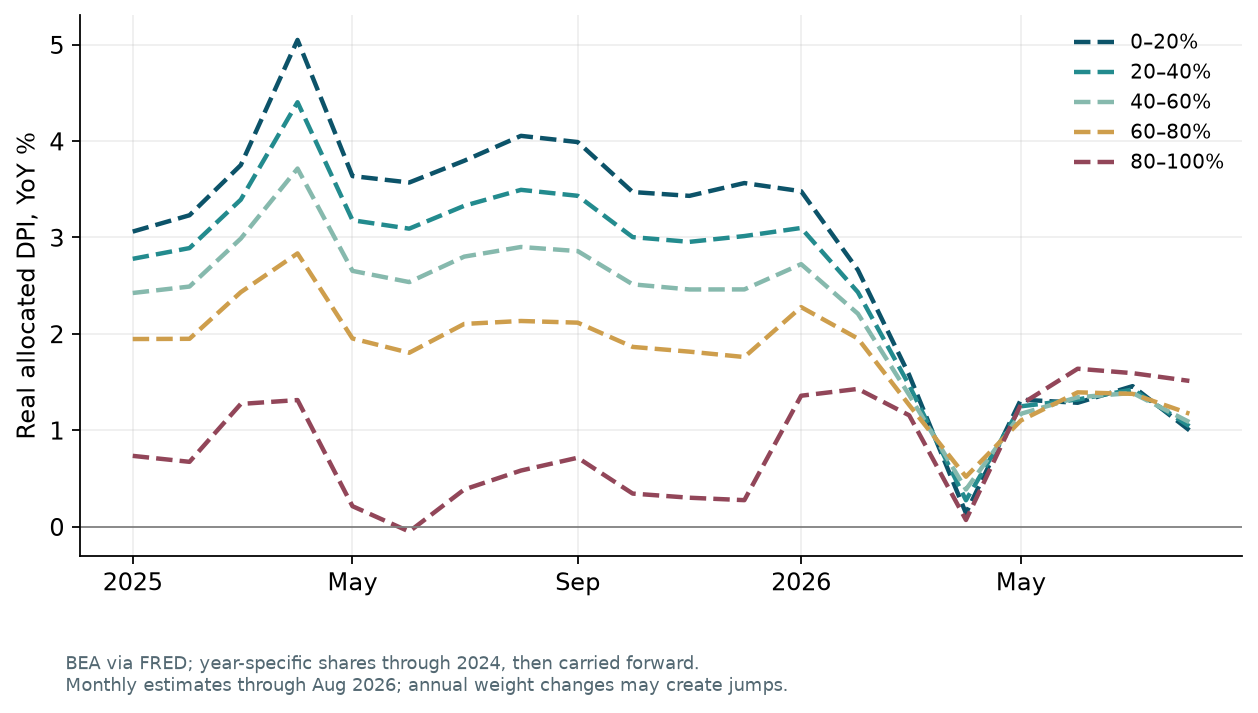

In [4]:
distribution = pd.read_csv(download(
    'https://apps.bea.gov/data/special-topics/distribution-of-personal-income/national/summary-file.csv'))
distribution = distribution[distribution.Ranking == 'Equivalized Disposable Personal Income']
available_years = np.sort(distribution.loc[distribution['Income Concept'].eq('Disposable personal income'), 'Year'].unique())
INCOME_YEAR = int(available_years[-1])
components = {'compensation':'Compensation of employees',
    'proprietors':"Proprietors' income with inventory valuation",
    'rent':'Rental income of households with capital consumption adjustment',
    'interest':'Household interest income', 'dividends':'Household dividend income',
    'transfers':'Household current transfer receipts',
    'social_insurance':'Contributions for government social insurance, domestic', 'taxes':'Taxes'}

def shares(concept, year):
    rows = distribution[(distribution['Income Concept'] == concept) & (distribution.Year == year)]
    values = pd.to_numeric(rows.set_index('Quantile or Summary Metric').Value, errors='coerce')
    weights = values.reindex([q.replace('–','-') for q in Q])
    if weights.isna().all():  # Some components publish deciles: combine neighboring pairs.
        weights = pd.Series(values.reindex([f'{i}-{i+10}%' for i in range(0,100,10)]).to_numpy().reshape(5,2).sum(axis=1))
    assert weights.notna().all(), f'Missing distribution shares: {year}, {concept}'
    return (weights / weights.sum()).set_axis(Q)

income = macro[['dpi','pcepi',*components]].dropna()
signed = income[list(components)].copy()
signed[['social_insurance','taxes']] *= -1
allocated = pd.DataFrame(index=income.index, columns=Q, dtype=float)
allocation_year = pd.Series(index=income.index, dtype='Int64', name='BEA allocation year')
for year, monthly in signed.groupby(signed.index.year):
    eligible = available_years[available_years <= year]
    assert len(eligible), f'No BEA allocation available for or before {year}'
    weight_year = int(eligible[-1])  # Same year if published; otherwise the latest earlier year.
    weights = pd.DataFrame({name:shares(label, weight_year) for name,label in components.items()}).T
    residual = income.loc[monthly.index, 'dpi'] - monthly.sum(axis=1)
    allocated.loc[monthly.index] = monthly.dot(weights) + np.outer(residual, shares('Disposable personal income', weight_year))
    allocation_year.loc[monthly.index] = weight_year
assert np.allclose(allocated.sum(axis=1), income.dpi)
real_income = allocated.div(income.pcepi / 100, axis=0)
fig, ax = plt.subplots(figsize=(8,4.5))
line(ax, real_income.pct_change(12, fill_method=None)*100, 'Real allocated DPI, YoY %', INCOME_CHART_START, '--')
ax.axhline(0, color='grey', lw=.8)
show(fig, 1, f'BEA via FRED; year-specific shares through {INCOME_YEAR}, then carried forward.\nMonthly estimates through {income.index[-1]:%b %Y}; annual weight changes may create jumps.')

### 2. Nominal and real wage growth by wage quartile
Atlanta Fed matched-worker wages use 12-month smoothing. Deflate by the matching
12-month average of CPI inflation: `(1 + wage growth) / (1 + inflation) - 1`.

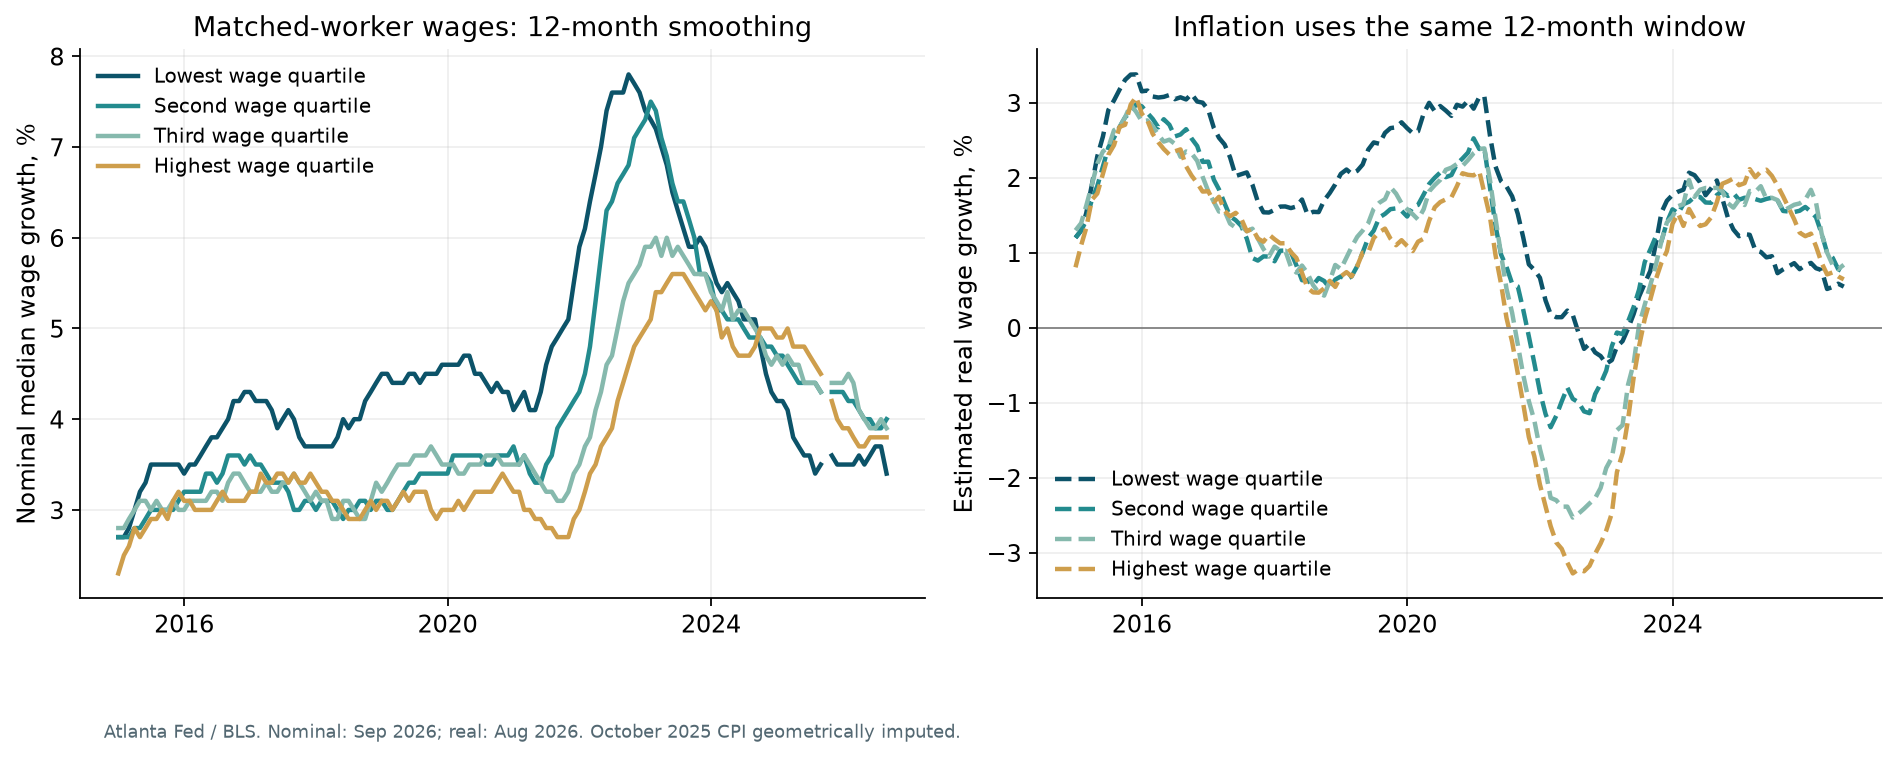

In [5]:
wages = pd.read_excel(download(
    'https://www.atlantafed.org/-/media/Project/Atlanta/FRBA/Documents/datafiles/chcs/wage-growth-tracker/wage-growth-data.xlsx'),
    sheet_name='Average Wage Quartile', header=2)
wages.index = pd.to_datetime(wages.iloc[:,0], errors='coerce')
wages = wages.loc[wages.index.notna()].iloc[:,1:5].apply(pd.to_numeric, errors='coerce')
wages.columns = ['Lowest wage quartile','Second wage quartile','Third wage quartile','Highest wage quartile']
wages = wages.loc[wages.index.to_period('M').end_time.normalize() <= AS_OF]
inflation = cpi.cpi.pct_change(12, fill_method=None).rolling(12).mean()
real_wages = ((1+wages/100).div(1+inflation, axis=0)-1)*100
fig, ax = plt.subplots(1,2)
line(ax[0], wages, 'Nominal median wage growth, %', '2015')
line(ax[1], real_wages.dropna(), 'Estimated real wage growth, %', '2015', '--')
ax[0].set_title('Matched-worker wages: 12-month smoothing', fontsize=12)
ax[1].set_title('Inflation uses the same 12-month window', fontsize=12)
ax[1].axhline(0, color='grey', lw=.8)
show(fig, 2, f'Atlanta Fed / BLS. Nominal: {wages.index[-1]:%b %Y}; real: {real_wages.dropna().index[-1]:%b %Y}. October 2025 CPI geometrically imputed.')

### 3. Energy burden and purchasing power after energy
Subtract nominal energy spending before deflating the remainder by CPI excluding energy.
This avoids subtracting the same energy inflation effect twice. Both resources measures include noncash income.

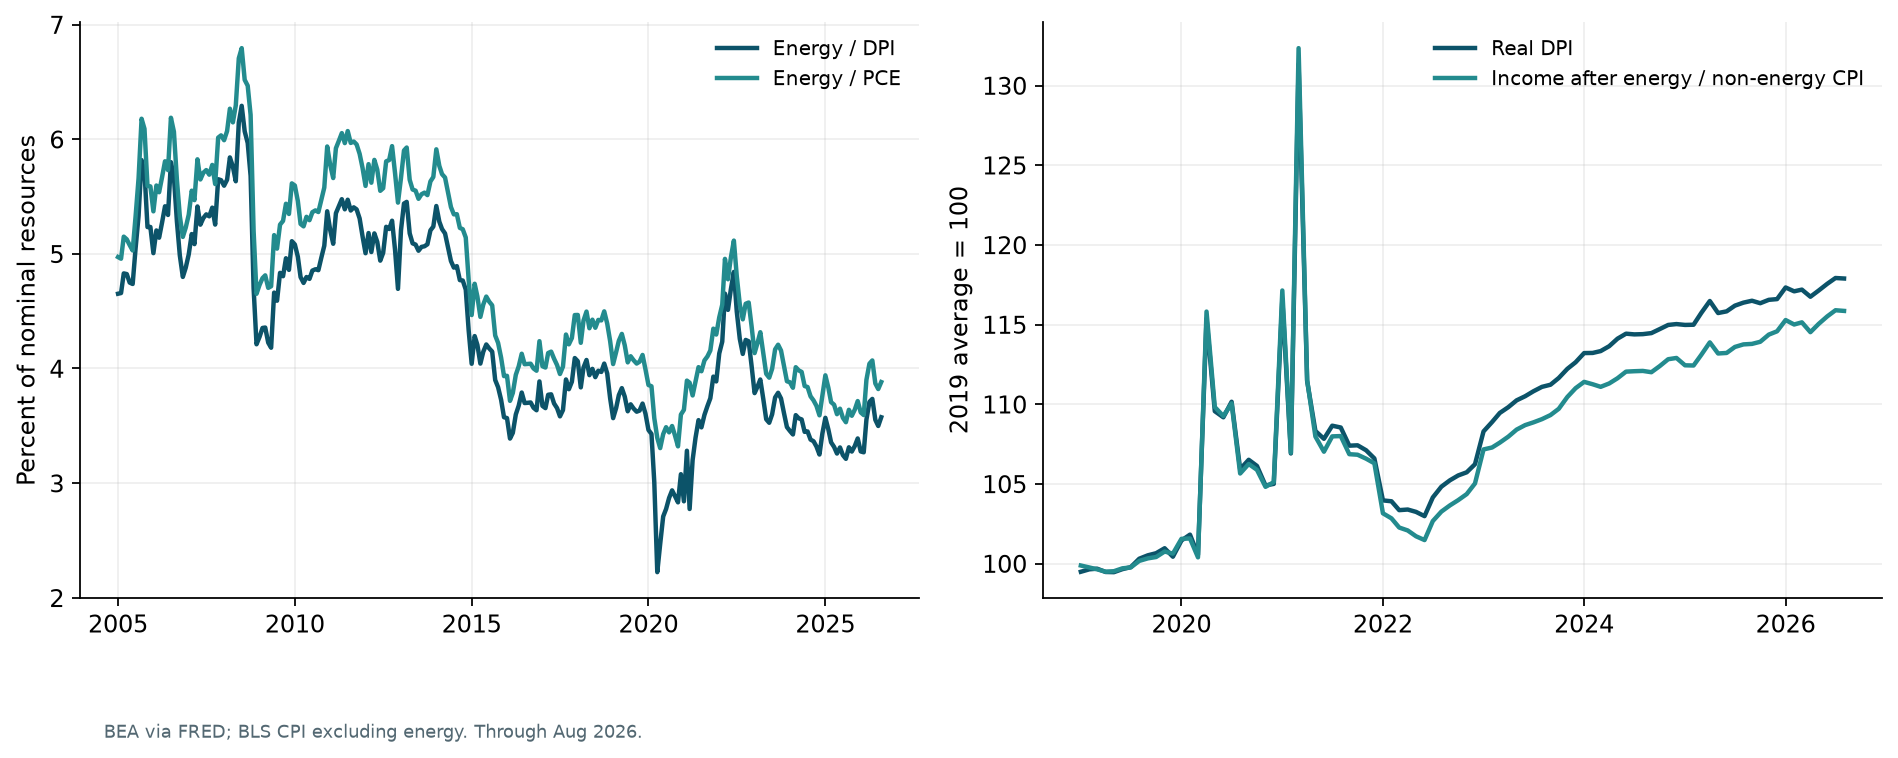

In [6]:
burden = pd.DataFrame({'Energy / DPI':macro.energy/macro.dpi*100, 'Energy / PCE':macro.energy/macro.pce*100})
resources = pd.DataFrame({'Real DPI':macro.rdpi,
    'Income after energy / non-energy CPI':(macro.dpi-macro.energy)/(cpi.cpi_ex_energy/100)})
resources = resources / resources.loc['2019'].mean()*100
fig, ax = plt.subplots(1,2)
line(ax[0], burden, 'Percent of nominal resources', '2005')
line(ax[1], resources, '2019 average = 100', '2019')
show(fig, 3, f'BEA via FRED; BLS CPI excluding energy. Through {macro.dpi.last_valid_index():%b %Y}.')

### 4. Direct energy exposure by income quintile
Historical CE expenditure shares; consumer units ranked by before-tax income differ from BEA income groups.

C:\Users\abour\.cache\codex-runtimes\codex-primary-runtime\dependencies\python\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


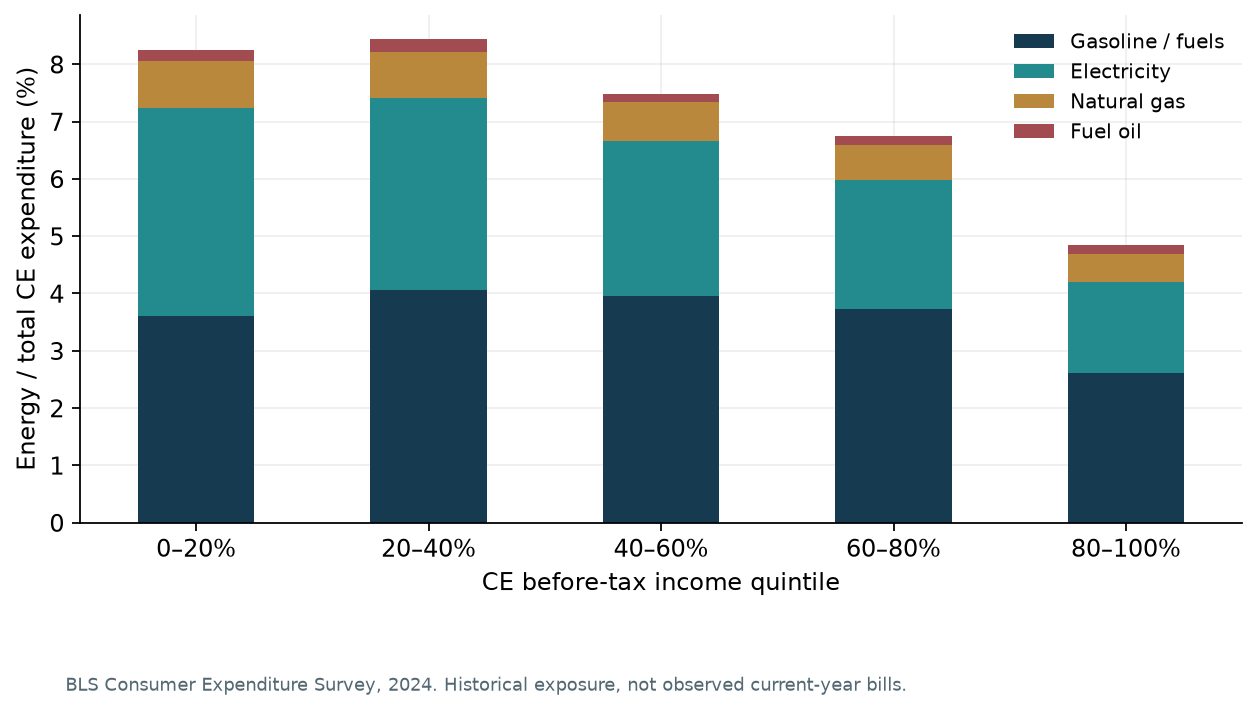

In [7]:
ce = pd.read_excel('ce_mean.xlsx', header=None)
CE_YEAR = int(re.search(r'\b20\d{2}\b', str(ce.iat[0,0])).group())
def ce_mean(label):
    row = ce.index[ce.iloc[:,0].astype(str).str.strip().eq(label)][0]
    return pd.Series(pd.to_numeric(ce.iloc[row+1,2:7]).to_numpy(), index=Q)
energy = pd.DataFrame({name:ce_mean(label) for name,label in {
    'Gasoline / fuels':'Gasoline and other fuels', 'Electricity':'Electricity',
    'Natural gas':'Natural gas', 'Fuel oil':'Fuel oil and other fuels'}.items()})
exposure = energy.div(ce_mean('Average annual expenditures'), axis=0)*100
fig, ax = plt.subplots(figsize=(8,4.5))
exposure.plot.bar(stacked=True, ax=ax, color=['#163b50','#238b8e','#ba883c','#a24b50'], rot=0)
ax.set(xlabel='CE before-tax income quintile', ylabel='Energy / total CE expenditure (%)')
ax.legend(frameon=False, fontsize=9)
show(fig, 4, f'BLS Consumer Expenditure Survey, {CE_YEAR}. Historical exposure, not observed current-year bills.')

### 5. Real income versus real spending growth

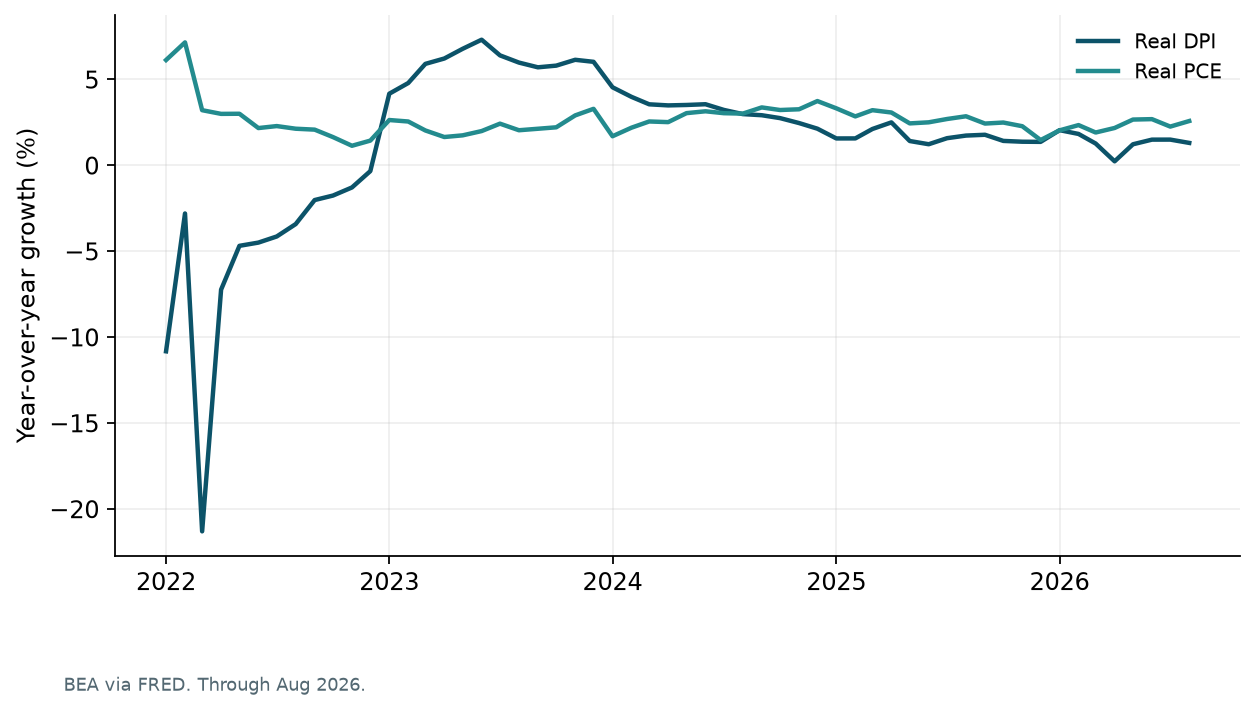

In [8]:
growth = macro[['rdpi','rpce']].rename(columns={'rdpi':'Real DPI','rpce':'Real PCE'}).pct_change(12, fill_method=None)*100
fig, ax = plt.subplots(figsize=(8,4.5))
line(ax, growth, 'Year-over-year growth (%)', '2022')
show(fig, 5, f'BEA via FRED. Through {macro.rpce.last_valid_index():%b %Y}.')

### 6. Aggregate wealth and liquidity relative to income
DFA stocks are converted from millions to billions. Denominators average three complete monthly
annualized flows. Liquid assets are deposits plus money-market funds.

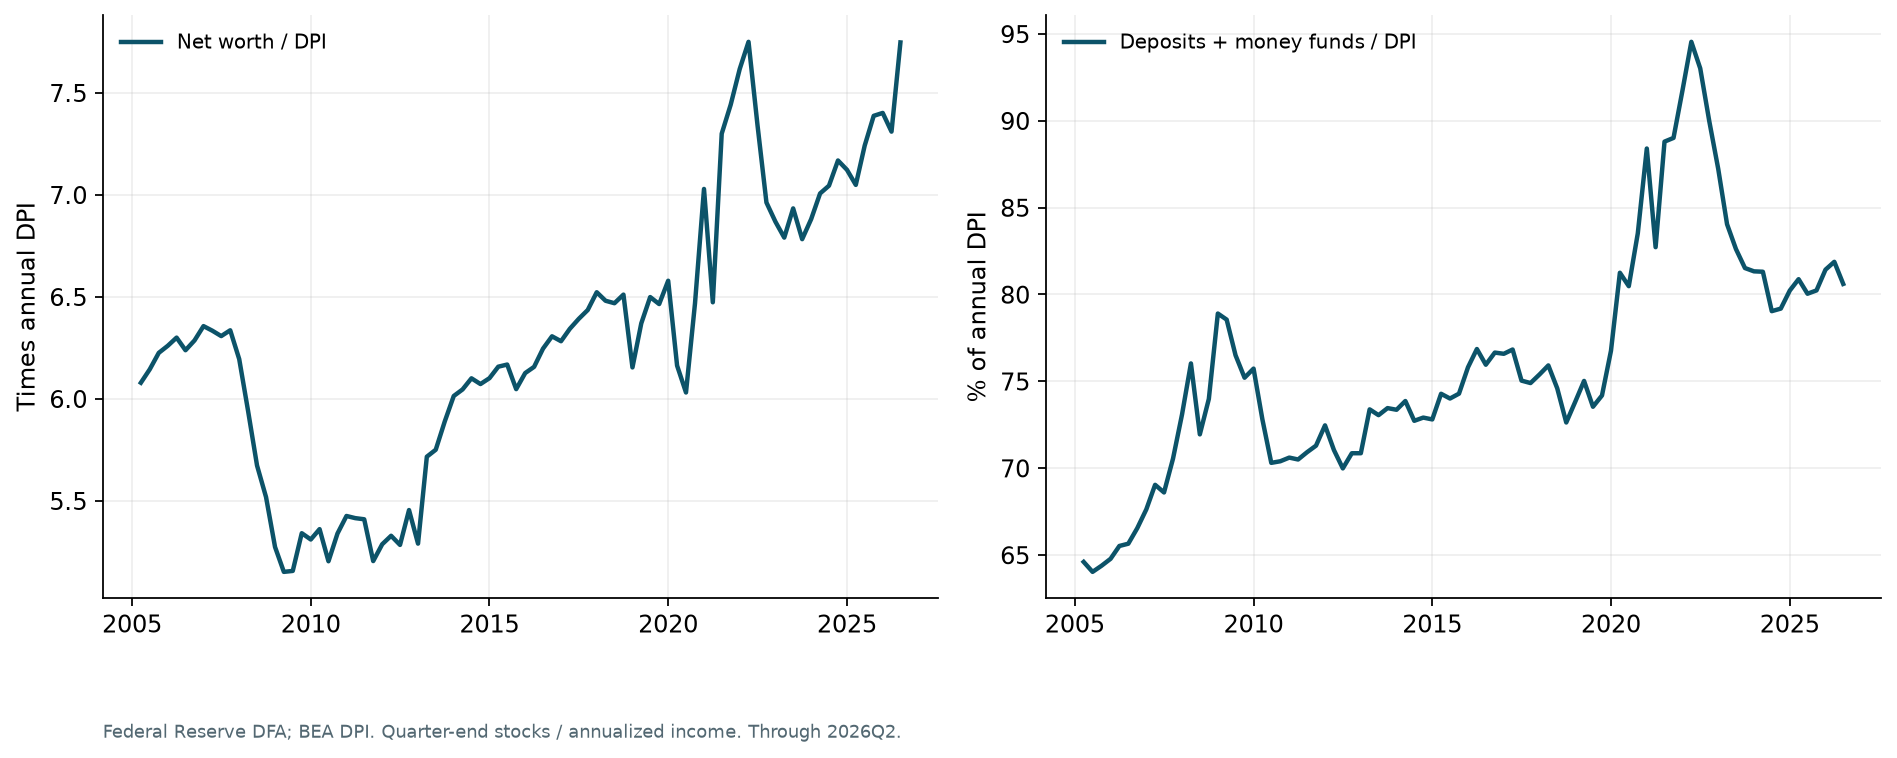

In [9]:
with zipfile.ZipFile(download('https://www.federalreserve.gov/releases/z1/dataviz/download/zips/dfa.zip')) as archive:
    dfa = pd.read_csv(archive.open('dfa-income-levels-detail.csv'))
dfa['quarter'] = pd.PeriodIndex(dfa.Date.str.replace(':',''), freq='Q')
dfa = dfa.loc[dfa.quarter.dt.end_time.dt.normalize() <= AS_OF].copy()
dfa['group'] = dfa.Category.map(dict(zip(
    ['pct00to20','pct20to40','pct40to60','pct60to80','pct80to99','pct99to100'], Q+[Q[-1]])))
dfa['Liquid assets'] = dfa.Deposits + dfa['Money market fund shares']
assets = dfa.groupby(['quarter','group'])[['Net worth','Liquid assets']].sum()/1000
totals = assets.groupby('quarter').sum()
flows = quarterly(macro[['dpi','pce','pcepi']])
common = totals.index.intersection(flows.index)
totals, flows = totals.loc[common], flows.loc[common]
ratios = pd.DataFrame({'Net worth / DPI':totals['Net worth']/flows.dpi,
                      'Deposits + money funds / DPI':totals['Liquid assets']/flows.dpi*100})
fig, ax = plt.subplots(1,2)
line(ax[0], dates(ratios.iloc[:,[0]]), 'Times annual DPI', '2005')
line(ax[1], dates(ratios.iloc[:,[1]]), '% of annual DPI', '2005')
show(fig, 6, f'Federal Reserve DFA; BEA DPI. Quarter-end stocks / annualized income. Through {common[-1]}.')

### 7. Real wealth and liquidity by income group
DFA income ranks differ from BEA equivalized-DPI ranks. Values are group totals, not household medians.

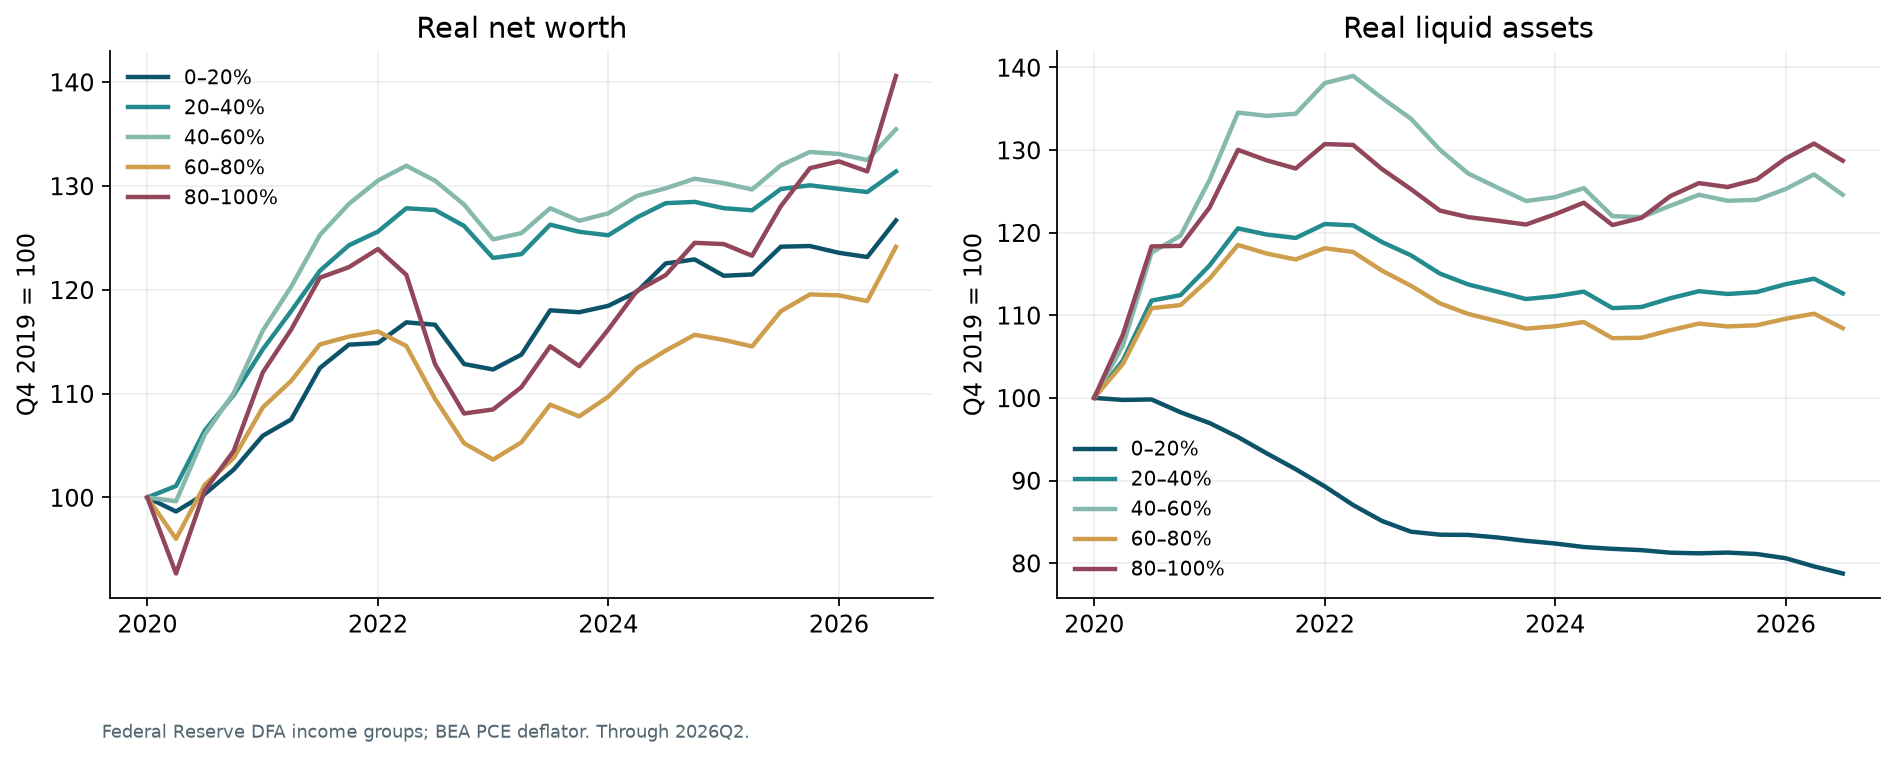

In [10]:
wealth = assets['Net worth'].unstack().reindex(index=common, columns=Q).div(flows.pcepi/100, axis=0)
liquidity = assets['Liquid assets'].unstack().reindex(index=common, columns=Q).div(flows.pcepi/100, axis=0)
fig, ax = plt.subplots(1,2)
for a, data, title in zip(ax, [wealth,liquidity], ['Real net worth','Real liquid assets']):
    line(a, dates(data/data.loc['2019Q4']*100), 'Q4 2019 = 100', '2019-10-01')
    a.set_title(title)
show(fig, 7, f'Federal Reserve DFA income groups; BEA PCE deflator. Through {common[-1]}.')

### 8. Months of spending covered by liquid assets and net worth
`Months = 12 × assets / (annualized PCE × CE aggregate spending share)`.
Ratios of group totals, not typical-household cash runway; CE and DFA income groups are approximate matches.
Net worth includes illiquid assets. Historical CE shares approximate the distribution of current PCE.

C:\Users\abour\.cache\codex-runtimes\codex-primary-runtime\dependencies\python\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


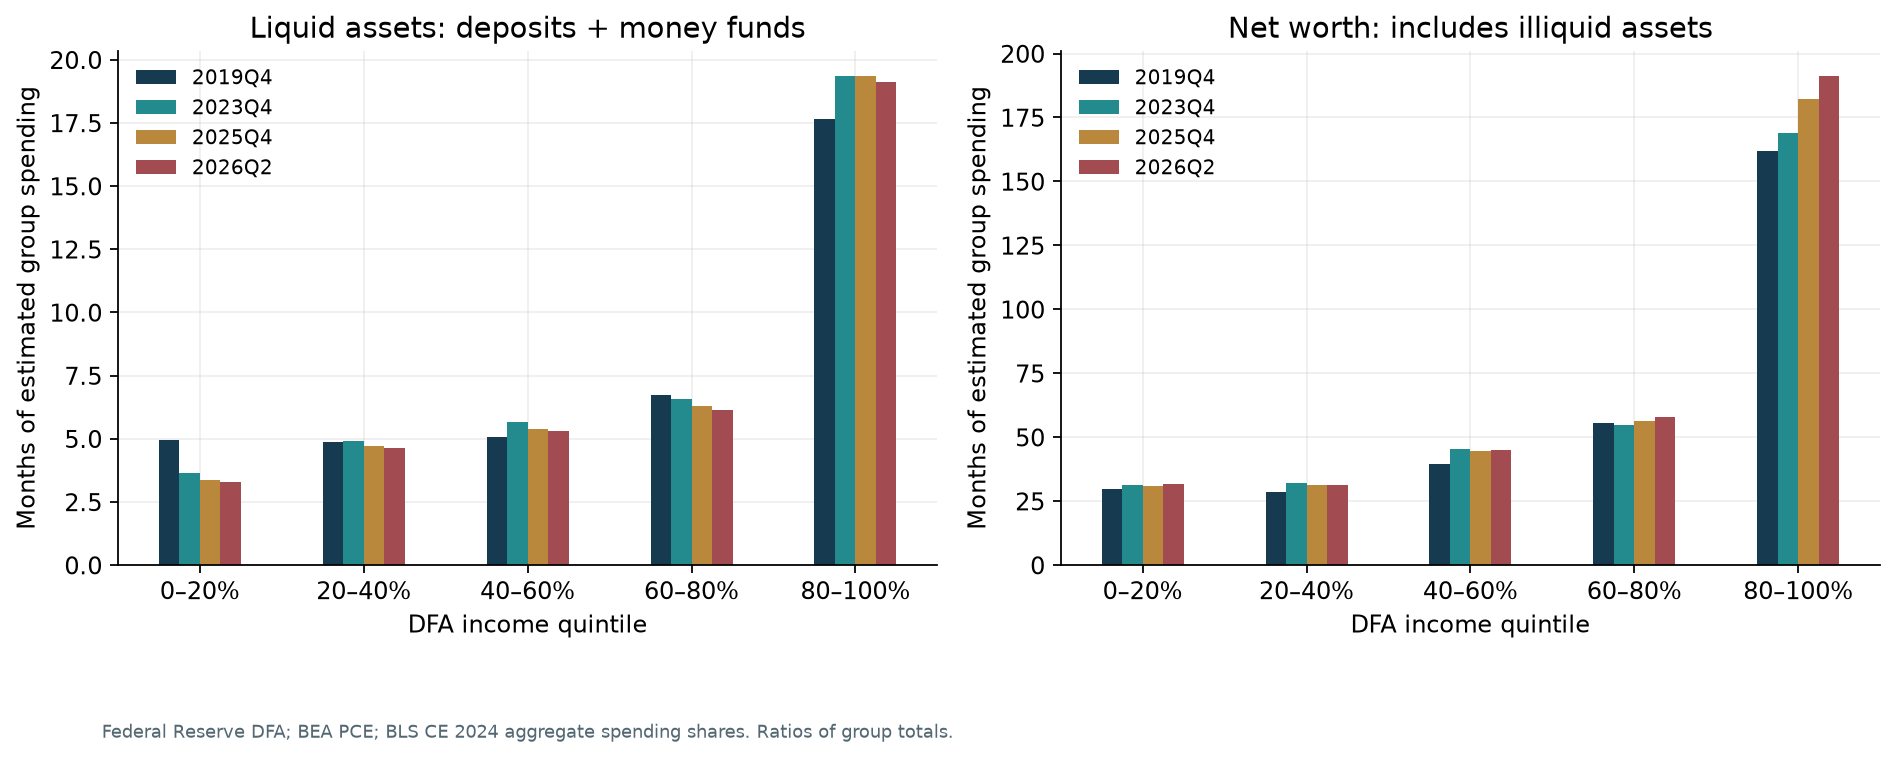

In [11]:
ce_shares = pd.read_excel('ce_shares.xlsx', header=None)
assert str(CE_YEAR) in str(ce_shares.iat[0,0]), 'The two CE files must cover the same year'
row = ce_shares.loc[ce_shares.iloc[:,0].astype(str).str.strip().eq('Annual aggregate expenditures')].iloc[0]
spending_share = pd.Series(pd.to_numeric(row.iloc[2:7]).to_numpy(), index=Q)
spending_share /= spending_share.sum()
denominator = pd.DataFrame(np.outer(flows.pce, spending_share), index=common, columns=Q)
liquid_coverage = 12*assets['Liquid assets'].unstack().reindex(index=common, columns=Q)/denominator
wealth_coverage = 12*assets['Net worth'].unstack().reindex(index=common, columns=Q)/denominator
quarters = list(dict.fromkeys([pd.Period(q,'Q') for q in ['2019Q4','2023Q4','2025Q4']]+[common[-1]]))
fig, ax = plt.subplots(1,2)
for a, data, title in zip(ax, [liquid_coverage,wealth_coverage],
                        ['Liquid assets: deposits + money funds','Net worth: includes illiquid assets']):
    data.loc[quarters].T.rename(columns=str).plot.bar(ax=a, rot=0, color=['#163b50','#238b8e','#ba883c','#a24b50'])
    a.set(xlabel='DFA income quintile', ylabel='Months of estimated group spending', title=title)
    a.legend(fontsize=9, frameon=False)
show(fig, 8, f'Federal Reserve DFA; BEA PCE; BLS CE {CE_YEAR} aggregate spending shares. Ratios of group totals.')

### 9. Debt balances and debt relative to income
NY Fed credit-report balances differ from DFA liabilities. A mortgage-servicing reporting gap
affected Q2 2026 balances; that decline should not be read as household deleveraging.

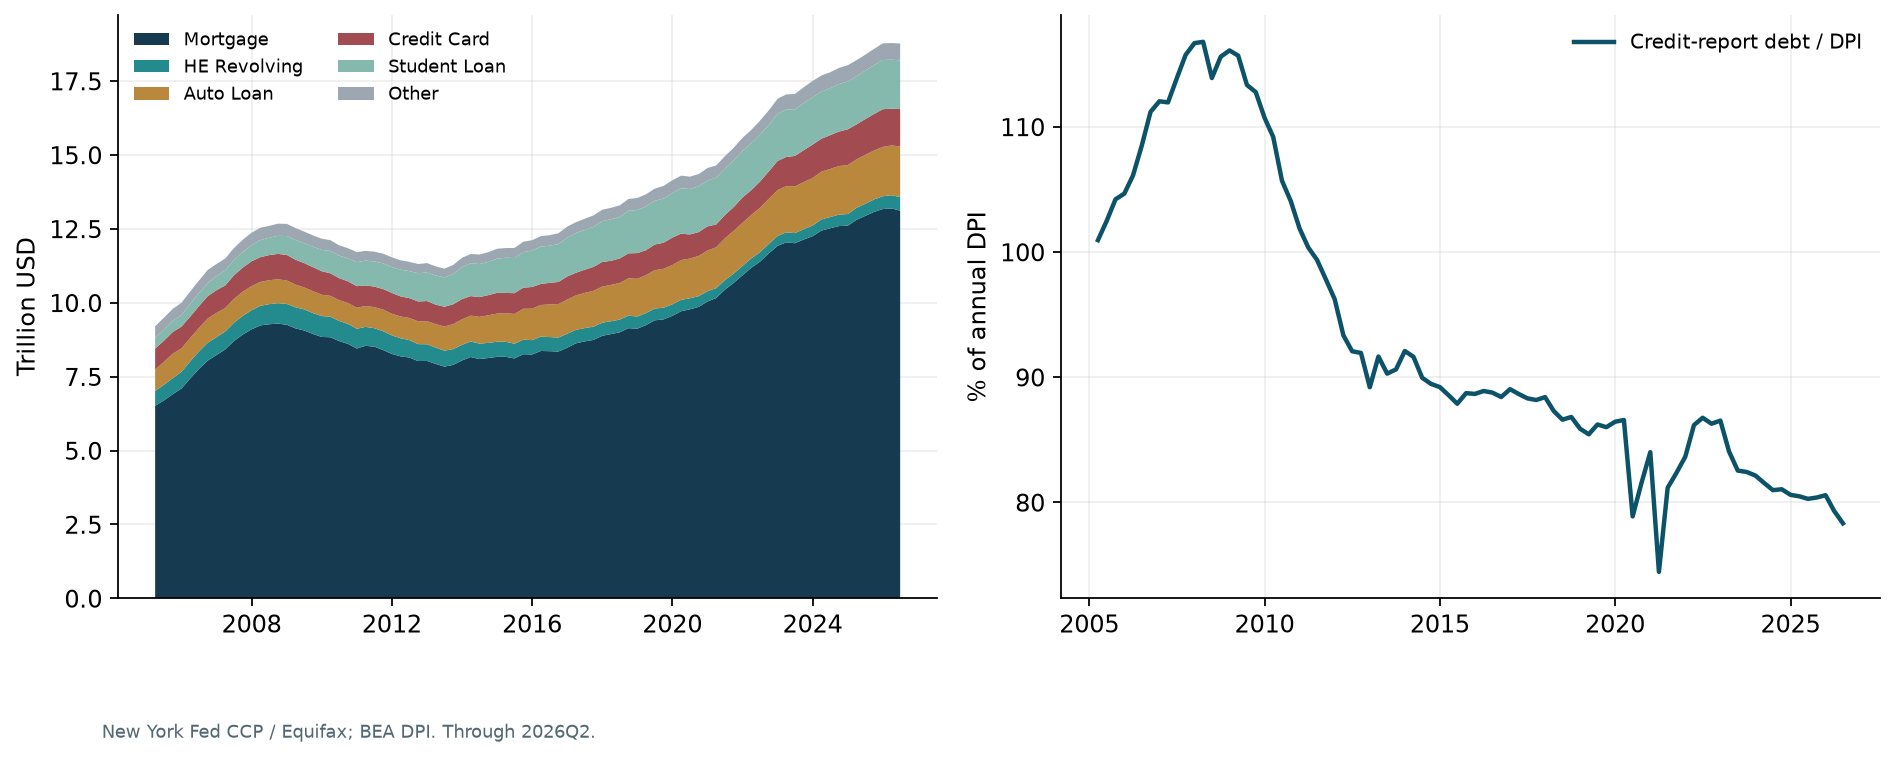

In [12]:
# Find the newest published quarterly workbook (unpublished links return HTML or 404).
for quarter in pd.period_range(end=AS_OF.to_period('Q')-1, periods=4, freq='Q')[::-1]:
    url = f'https://www.newyorkfed.org/medialibrary/interactives/householdcredit/data/xls/hhd_c_report_{str(quarter).lower()}.xlsx'
    response = requests.get(url, timeout=45)
    if response.status_code == 404:
        continue
    response.raise_for_status()
    if response.content.startswith(b'PK'):
        raw = pd.read_excel(BytesIO(response.content), sheet_name='Page 3 Data', header=None)
        break
else:
    raise RuntimeError('No recent NY Fed debt workbook found')
is_quarter = raw.iloc[:,0].astype(str).str.fullmatch(r'\d{2}:Q[1-4]')
debt = raw.loc[is_quarter].copy()
debt.columns = raw.iloc[debt.index[0]-1].astype(str).str.strip()
debt.index = pd.PeriodIndex('20'+debt.iloc[:,0].astype(str).str.replace(':',''), freq='Q')
debt = debt.iloc[:,1:].apply(pd.to_numeric, errors='coerce').dropna(axis=1, how='all')
debt = debt.loc[debt.index.end_time.normalize() <= AS_OF]
products = ['Mortgage','HE Revolving','Auto Loan','Credit Card','Student Loan','Other']
debt_ratio = debt.Total*1000/quarterly(macro.dpi)*100  # NY Fed trillions → BEA billions.
fig, ax = plt.subplots(1,2)
balances = dates(debt.loc['2005':])
ax[0].stackplot(balances.index, *[balances[c] for c in products], labels=products,
    colors=['#163b50','#238b8e','#ba883c','#a24b50','#86b9ad','#9ca7b1'])
ax[0].set_ylabel('Trillion USD'); ax[0].legend(fontsize=8, ncol=2, frameon=False)
line(ax[1], dates(debt_ratio.to_frame('Credit-report debt / DPI')), '% of annual DPI', '2005')
show(fig, 9, f'New York Fed CCP / Equifax; BEA DPI. Through {debt.index[-1]}.')

### 10. Required debt-service payments relative to income
Current Federal Reserve methodology from 2005, including mortgage escrow. No splice to the retired series.

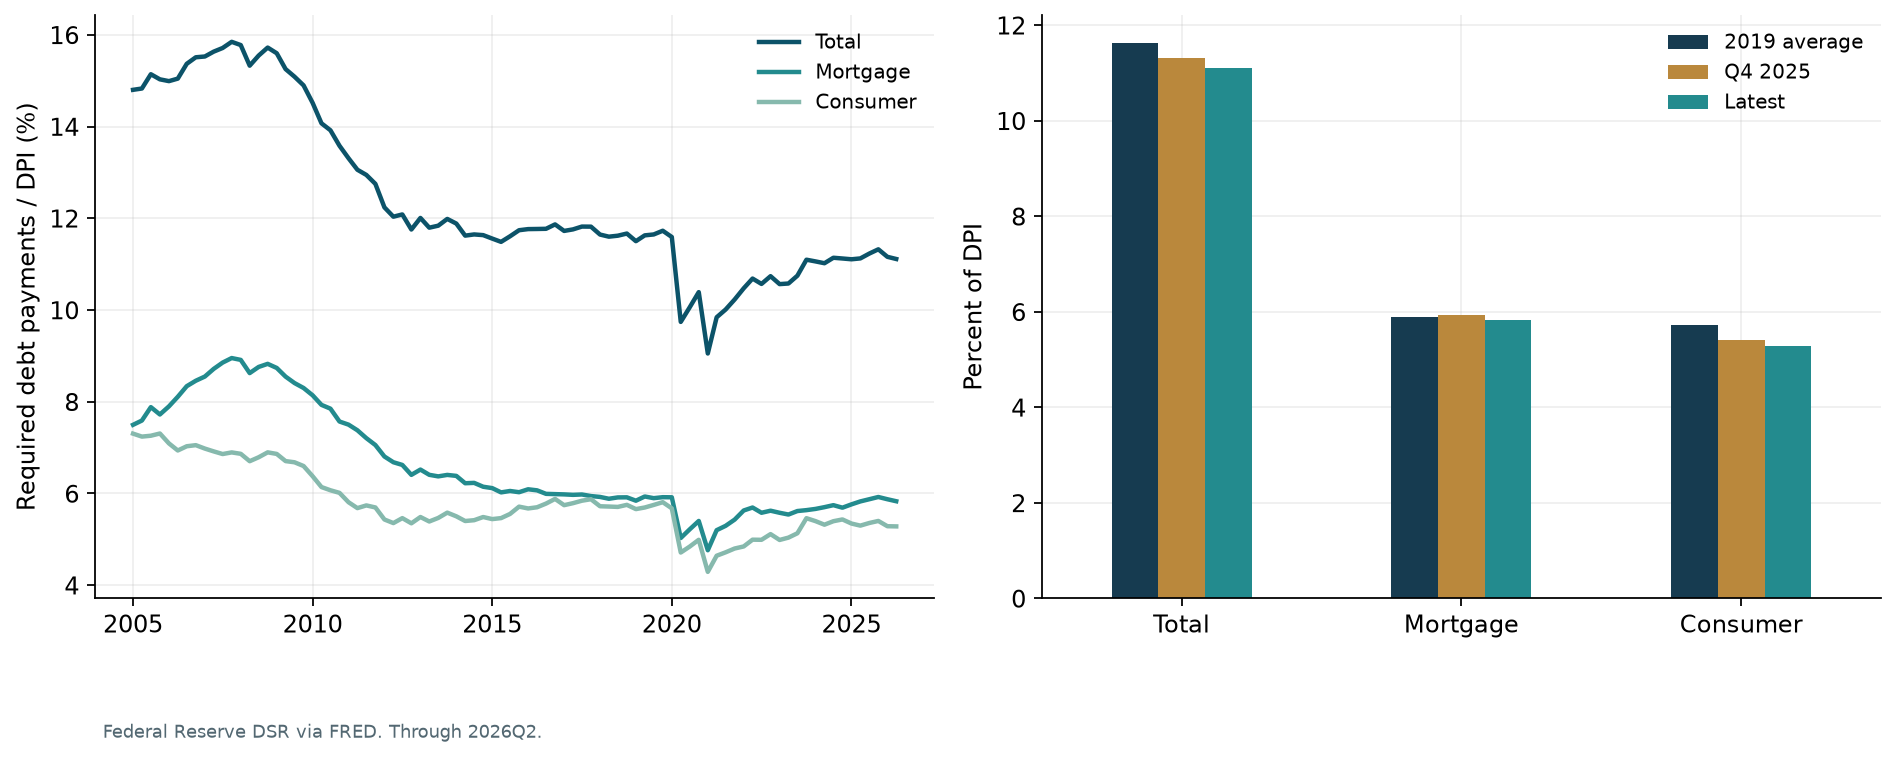

In [13]:
dsr = macro[['Total','Mortgage','Consumer']].dropna()
dsr = dsr.loc[dsr.index.to_period('Q').end_time.normalize() <= AS_OF]
comparison = pd.DataFrame({'2019 average':dsr.loc['2019'].mean(),
                           'Q4 2025':dsr.loc['2025'].iloc[-1], 'Latest':dsr.iloc[-1]})
fig, ax = plt.subplots(1,2)
line(ax[0], dsr, 'Required debt payments / DPI (%)', '2005')
comparison.plot.bar(ax=ax[1], rot=0, color=['#163b50','#ba883c','#238b8e'])
ax[1].set_ylabel('Percent of DPI'); ax[1].legend(fontsize=9, frameon=False)
show(fig, 10, f'Federal Reserve DSR via FRED. Through {dsr.index[-1].to_period("Q")}.')